In [1]:

from pathlib import Path
import sys

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Add project root so we can import src modules.
PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import load_and_clean_data

# Configure visualization defaults.
sns.set_theme(style="whitegrid")

# Load cleaned Summer Olympics data.
df = load_and_clean_data(
    data_dir=PROJECT_ROOT / "data",
    season="Summer"
)

print("Dataset shape:", df.shape)
print("Year range:", df["Year"].min(), "-", df["Year"].max())
print("Unique athletes:", df["ID"].nunique())
print("Olympic editions:", df["Year"].nunique())

display(df.head())


Dataset shape: (221167, 16)
Year range: 1896 - 2016
Unique athletes: 116776
Olympic editions: 29


,ID,Name,Sex,Age,Height,Weight,Team,NOC,Games,Year,Season,City,Sport,Event,Medal,region
0,1,A Dijiang,M,24.0,180.0,80.0,China,CHN,1992 Summer,1992,Summer,Barcelona,Basketball,Basketball Men's Basketball,NaN,China
1,2,A Lamusi,M,23.0,170.0,60.0,China,CHN,2012 Summer,2012,Summer,London,Judo,Judo Men's Extra-Lightweight,NaN,China
2,3,Gunnar Nielsen Aaby,M,24.0,NaN,NaN,Denmark,DEN,1920 Summer,1920,Summer,Antwerpen,Football,Football Men's Football,NaN,Denmark
3,4,Edgar Lindenau Aabye,M,34.0,NaN,NaN,Denmark/Sweden,DEN,1900 Summer,1900,Summer,Paris,Tug-Of-War,Tug-Of-War Men's Tug-Of-War,Gold,Denmark
4,8,"Cornelia ""Cor"" Aalten (-Strannood)",F,18.0,168.0,NaN,Netherlands,NED,1932 Summer,1932,Summer,Los Angeles,Athletics,Athletics Women's 100 metres,NaN,Netherlands


=== DATASET INFORMATION ===
<class 'pandas.DataFrame'>
RangeIndex: 221167 entries, 0 to 221166
Data columns (total 16 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   ID      221167 non-null  int64  
 1   Name    221167 non-null  str    
 2   Sex     221167 non-null  str    
 3   Age     212137 non-null  float64
 4   Height  170667 non-null  float64
 5   Weight  168661 non-null  float64
 6   Team    221167 non-null  str    
 7   NOC     221167 non-null  str    
 8   Games   221167 non-null  str    
 9   Year    221167 non-null  int64  
 10  Season  221167 non-null  str    
 11  City    221167 non-null  str    
 12  Sport   221167 non-null  str    
 13  Event   221167 non-null  str    
 14  Medal   34077 non-null   str    
 15  region  221167 non-null  str    
dtypes: float64(3), int64(2), str(11)
memory usage: 49.3 MB

=== NUMERICAL SUMMARY ===


,ID,Age,Height,Weight,Year
count,221167.000000,212137.000000,170667.000000,168661.000000,221167.000000
mean,68016.867403,25.549367,175.515560,70.688298,1976.602486
std,39144.711847,6.434035,10.914843,14.805242,30.820855
min,1.000000,10.000000,127.000000,25.000000,1896.000000
25%,34011.500000,21.000000,168.000000,60.000000,1960.000000
50%,68342.000000,24.000000,175.000000,70.000000,1984.000000
75%,101904.500000,28.000000,183.000000,79.000000,2000.000000
max,135568.000000,97.000000,226.000000,214.000000,2016.000000



=== MISSING VALUES ===


,Missing Count,Missing Percentage
ID,0,0.00
Name,0,0.00
Sex,0,0.00
Age,9030,4.08
Height,50500,22.83
Weight,52506,23.74
Team,0,0.00
NOC,0,0.00
Games,0,0.00
Year,0,0.00


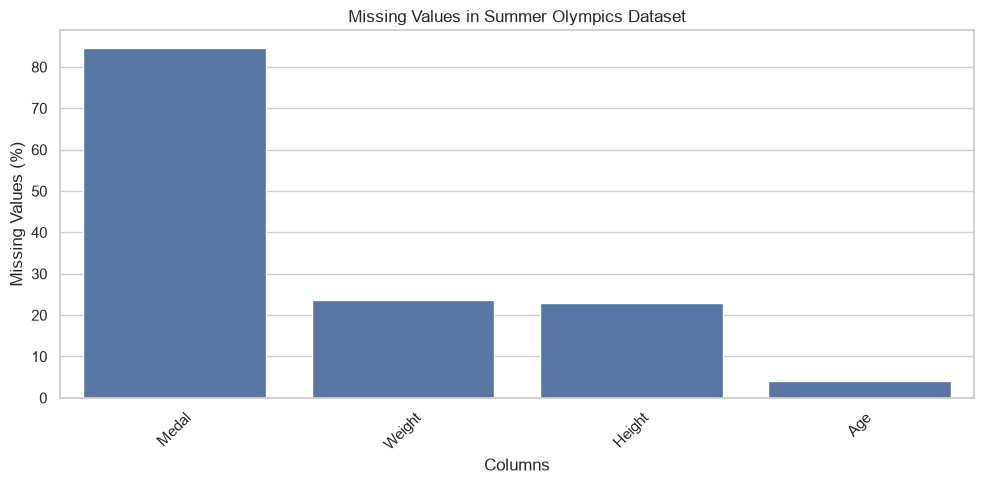

In [2]:

# ============================================================
# EDA 1: DATASET OVERVIEW AND MISSING VALUES
# ============================================================

print("=== DATASET INFORMATION ===")
df.info()

print("\n=== NUMERICAL SUMMARY ===")
display(df.describe())

print("\n=== MISSING VALUES ===")

missing = pd.DataFrame({
    "Missing Count": df.isna().sum(),
    "Missing Percentage": (
        df.isna().mean() * 100
    ).round(2)
})

display(missing)

# Visualize missing values.
missing_plot = missing[
    missing["Missing Count"] > 0
].sort_values("Missing Percentage", ascending=False)

plt.figure(figsize=(10, 5))

sns.barplot(
    x=missing_plot.index,
    y=missing_plot["Missing Percentage"]
)

plt.title("Missing Values in Summer Olympics Dataset")
plt.xlabel("Columns")
plt.ylabel("Missing Values (%)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


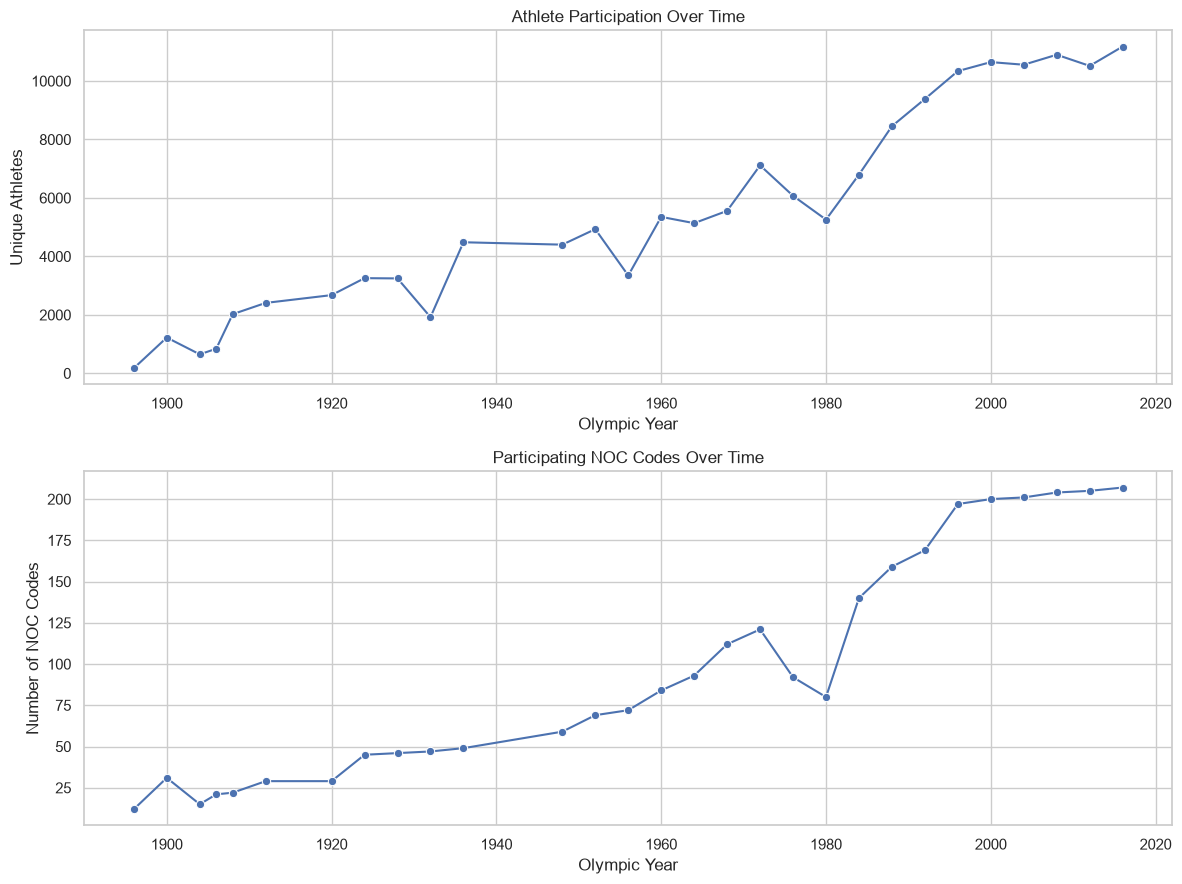

,Year,Nations,Athletes
19,1980,80,5259
20,1984,140,6798
21,1988,159,8454
22,1992,169,9386
23,1996,197,10339
24,2000,200,10647
25,2004,201,10557
26,2008,204,10899
27,2012,205,10517
28,2016,207,11179


In [3]:

# ============================================================
# EDA 2: OLYMPIC PARTICIPATION TRENDS
# ============================================================

from src.overall_analysis import get_participation_trend

participation = get_participation_trend(df)

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

sns.lineplot(
    data=participation,
    x="Year",
    y="Athletes",
    marker="o",
    ax=axes[0]
)

axes[0].set_title("Athlete Participation Over Time")
axes[0].set_xlabel("Olympic Year")
axes[0].set_ylabel("Unique Athletes")

sns.lineplot(
    data=participation,
    x="Year",
    y="Nations",
    marker="o",
    ax=axes[1]
)

axes[1].set_title("Participating NOC Codes Over Time")
axes[1].set_xlabel("Olympic Year")
axes[1].set_ylabel("Number of NOC Codes")

plt.tight_layout()
plt.show()

display(participation.tail(10))


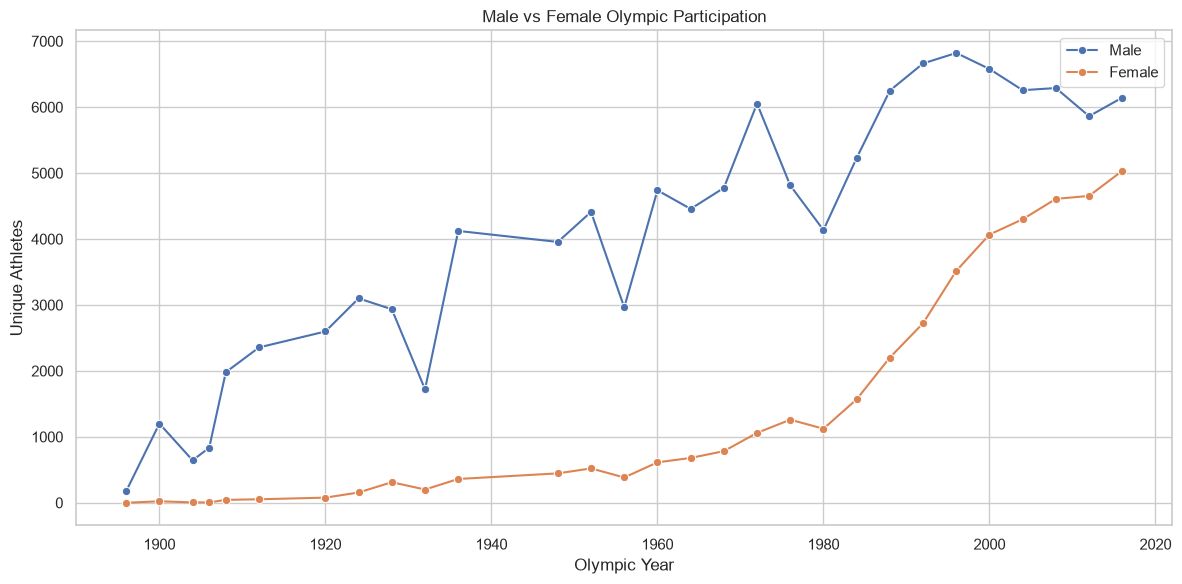

Sex,Year,Male,Female,Female_Percentage
19,1980,4136,1123,21.35
20,1984,5229,1569,23.08
21,1988,6251,2203,26.06
22,1992,6663,2723,29.01
23,1996,6822,3517,34.02
24,2000,6579,4068,38.21
25,2004,6257,4300,40.73
26,2008,6290,4609,42.29
27,2012,5863,4654,44.25
28,2016,6145,5034,45.03


In [4]:

# ============================================================
# EDA 3: GENDER PARTICIPATION
# ============================================================

from src.athlete_analysis import get_gender_participation_trend

gender = get_gender_participation_trend(df)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=gender,
    x="Year",
    y="Male",
    marker="o",
    label="Male"
)

sns.lineplot(
    data=gender,
    x="Year",
    y="Female",
    marker="o",
    label="Female"
)

plt.title("Male vs Female Olympic Participation")
plt.xlabel("Olympic Year")
plt.ylabel("Unique Athletes")
plt.legend()
plt.tight_layout()
plt.show()

# Female participation percentage.
gender["Female_Percentage"] = (
    gender["Female"]
    / (gender["Male"] + gender["Female"])
    * 100
).round(2)

display(gender.tail(10))


=== ATHLETE AGE STATISTICS ===


count    152341.00000
mean         25.90776
std           6.27722
min          10.00000
25%          22.00000
50%          25.00000
75%          29.00000
max          97.00000
Name: Age, dtype: float64

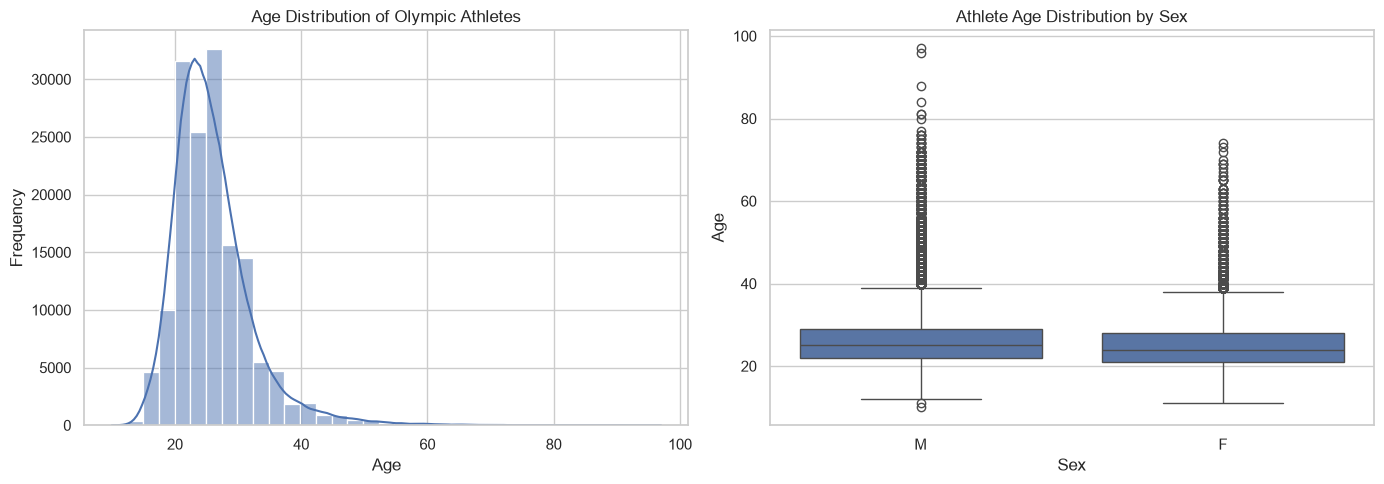

In [5]:

# ============================================================
# EDA 4: ATHLETE AGE DISTRIBUTION
# ============================================================

# Use unique athletes per Olympic year to avoid
# counting the same athlete multiple times in one edition.

age_data = (
    df.dropna(subset=["Age"])
    .drop_duplicates(subset=["Year", "ID"])
    .copy()
)

print("=== ATHLETE AGE STATISTICS ===")
display(age_data["Age"].describe())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Age distribution
sns.histplot(
    data=age_data,
    x="Age",
    bins=35,
    kde=True,
    ax=axes[0]
)

axes[0].set_title("Age Distribution of Olympic Athletes")
axes[0].set_xlabel("Age")
axes[0].set_ylabel("Frequency")

# Age distribution by sex
sns.boxplot(
    data=age_data,
    x="Sex",
    y="Age",
    order=["M", "F"],
    ax=axes[1]
)

axes[1].set_title("Athlete Age Distribution by Sex")
axes[1].set_xlabel("Sex")
axes[1].set_ylabel("Age")

plt.tight_layout()
plt.show()


=== TOP 15 SPORTS ===


Sport
Athletics        30536
Swimming         11935
Rowing           10223
Cycling           7540
Shooting          7471
Wrestling         6861
Football          6745
Sailing           6392
Fencing           6391
Boxing            6041
Hockey            5417
Gymnastics        5218
Canoeing          4769
Basketball        4536
Weightlifting     3923
Name: Athletes, dtype: int64

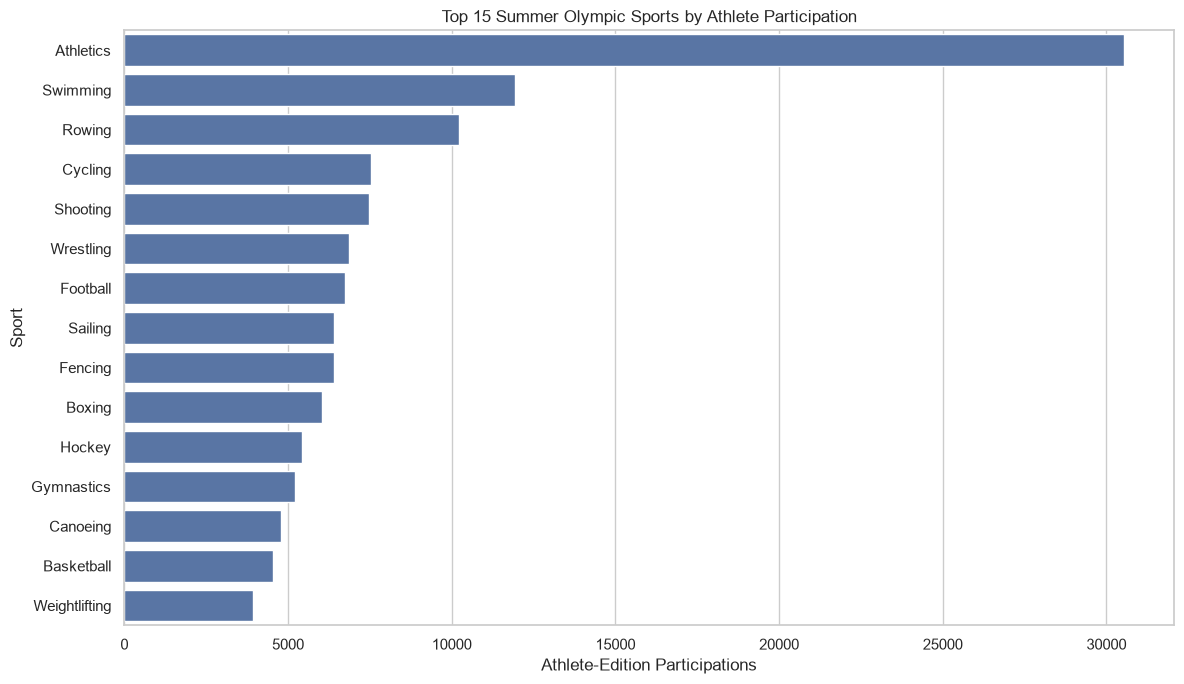

In [6]:

# ============================================================
# EDA 5: TOP 15 SPORTS BY ATHLETE PARTICIPATION
# ============================================================

# Count unique athlete IDs within each sport and year.
sport_participation = (
    df.groupby(["Year", "Sport"])["ID"]
    .nunique()
    .reset_index(name="Athletes")
)

top_sports = (
    sport_participation.groupby("Sport")["Athletes"]
    .sum()
    .sort_values(ascending=False)
    .head(15)
)

print("=== TOP 15 SPORTS ===")
display(top_sports)

plt.figure(figsize=(12, 7))

sns.barplot(
    x=top_sports.values,
    y=top_sports.index
)

plt.title("Top 15 Summer Olympic Sports by Athlete Participation")
plt.xlabel("Athlete-Edition Participations")
plt.ylabel("Sport")

plt.tight_layout()
plt.show()


=== TOP 15 COUNTRIES BY MEDAL AWARDS ===


Medal,region,Gold,Silver,Bronze,Total
0,USA,1071,819,719,2609
1,Russia,593,504,495,1592
2,Germany,453,467,505,1425
3,UK,318,333,312,963
4,France,247,277,312,836
5,Italy,230,191,216,637
8,Sweden,171,204,206,581
6,China,228,163,155,546
9,Australia,154,177,201,532
7,Hungary,178,155,173,506


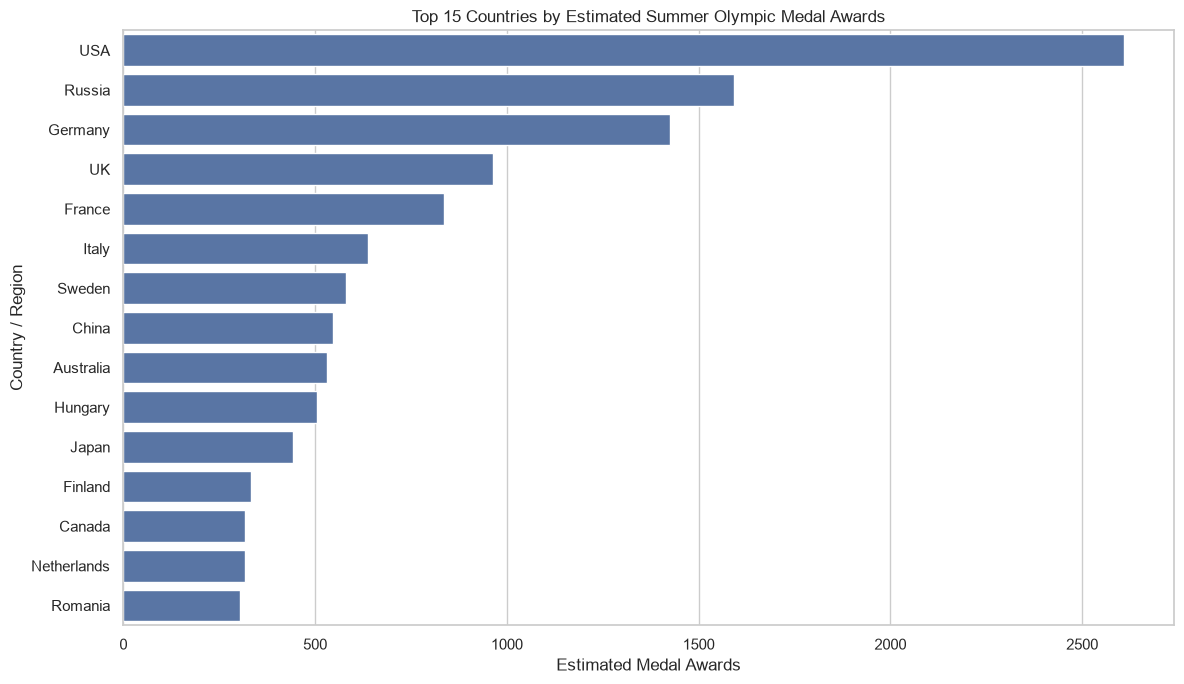

In [7]:

# ============================================================
# EDA 6: TOP 15 COUNTRIES BY MEDAL AWARDS
# ============================================================

from src.medal_analysis import get_medal_tally

# Preliminary dataset-derived medal awards.
medal_tally = get_medal_tally(df)

top_countries = (
    medal_tally.nlargest(15, "Total")
    .sort_values("Total", ascending=False)
)

print("=== TOP 15 COUNTRIES BY MEDAL AWARDS ===")
display(top_countries)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_countries,
    x="Total",
    y="region"
)

plt.title("Top 15 Countries by Estimated Summer Olympic Medal Awards")
plt.xlabel("Estimated Medal Awards")
plt.ylabel("Country / Region")

plt.tight_layout()
plt.show()
